# Estimating σ²: how much prices move per second

The Avellaneda–Stoikov (A–S) market maker needs to know how volatile the price is. That's σ², the **variance of the price per second**. It shapes our quotes in two ways:

- **Reservation price** $r = S - q\gamma\sigma^2(T-t)$: the more prices move, the harder we lean our quotes to get rid of inventory $q$.
- **Spread**: the more prices move, the wider we quote.

Prices get much busier as the race approaches, so we estimate a separate σ² for each time bin before the off. We use January 2025 only, and measure everything in **log-odds**.

**The plan**

1. Every 5 seconds from 350 s to 30 s before the off, record each runner's mid price.
2. Take the change in the mid price between neighbouring samples.
3. Keep a change only if the runner's odds were between 1.2 and 6.0 when it started.
4. In each time bin, compute the variance of those changes and divide by 5 to get a variance per second.
5. Add 95% confidence intervals, check the estimate is stable from day to day, and print a table to paste into `strategies/_final-strategy.py`.
6. Check that 5 seconds is a sensible step length.

## Prices in log-odds

For a runner whose best back odds are $B$ and best lay odds are $L$, the mid price is the average of the two implied probabilities:

$$S = \tfrac12\left(\frac1B + \frac1L\right)$$

We convert it to log-odds:

$$x = \ln\frac{S}{1-S}$$

**Why log-odds?** A probability is stuck between 0 and 1, so its moves shrink near the edges: a favourite at odds of 1.25 can't move as far in probability as a dog at 3.0. Log-odds stretch the scale so moves are comparable for favourites and longer shots, and there are no walls for the price to bump into, so treating it as a random walk makes sense.

A handy consequence: our odds filter (mid odds $1/S$ between 1.2 and 6.0) becomes the symmetric range $-\ln 5 \le x \le \ln 5$, about ±1.61 in log-odds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.lines import Line2D

# Project root = the folder that holds data/ (works whether this runs from research/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
FILES = sorted((ROOT / "data/processed/market_stream/Jan").glob("*/*/*.parquet"))   # one file per race

GRID = np.arange(350, 29, -5)       # sample times in seconds before the off: 350, 345, ..., 30
STEP = 5                            # seconds between samples
MIN_ODDS, MAX_ODDS = 1.2, 6.0       # only runners the strategy would quote
BIN_EDGES = [30, 45, 60, 90, 120, 180, 240, 300, 350]   # time bins, seconds before the off
N_BOOT = 1000                       # bootstrap repeats
rng = np.random.default_rng(42)     # fixed seed so the confidence intervals are reproducible

# Chart style: one colour for our estimate, greys for everything else, a light hairline grid
BLUE = "#2a78d6"                    # our estimate
GREY = "#898781"                    # an alternative we compare it with
LIGHT = "#c3c2b7"                   # background detail: every book update, single days, axis lines
INK, INK_2 = "#0b0b0b", "#52514e"   # headlines; labels and tick numbers
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle):
    # A bold headline that states the finding, then a smaller line saying what is plotted
    ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, 10), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold", pad=16 + 14 * (subtitle.count("\n") + 1))


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)


print(f"{len(FILES):,} January WIN markets")

4,072 January WIN markets


## Step 1: Each runner's mid price every 5 seconds

The order book updates at irregular times, often several times a second. To get evenly spaced observations we sample it at fixed times: 350, 345, …, 30 seconds before the off. The "mid at time $t$" comes from the **latest book update at or before $t$**, which is exactly what the strategy would see at that moment.

`pd.merge_asof` does this lookup: for each sample time it finds the most recent book update at or before it, separately for each runner (`by="selection_id"`).

Two details:

- **Scheduled off.** Some races had their start time changed (almost always hours beforehand), so we use the market's final `market_time`.
- **Suspended markets.** A mid only counts if the market was `OPEN` at that moment. If it was suspended (for example, after a scratching or once the race had started), the mid is left missing.

In [2]:
def mids_on_grid(path, grid=GRID):
    # Mid price of every runner at each time in `grid` (seconds before the off), one row per runner per time
    book = pd.read_parquet(path, columns=["publish_time", "market_time", "status",
                                          "selection_id", "back_price_1", "lay_price_1"])
    # A market that never had a price (one abandoned race) stores empty price columns, so force numbers
    book = book.astype({"back_price_1": float, "lay_price_1": float})
    off = book["market_time"].iloc[-1]          # scheduled off (its final value)

    # One row per runner per sample time
    samples = pd.MultiIndex.from_product([book["selection_id"].unique(), grid],
                                         names=["selection_id", "ttj"]).to_frame(index=False)
    samples["time"] = off - pd.to_timedelta(samples["ttj"], unit="s")

    # Attach the latest book update at or before each sample time
    # (merge_asof needs both clocks at the same precision, so put both in nanoseconds)
    samples["time"] = samples["time"].dt.as_unit("ns")
    book["publish_time"] = book["publish_time"].dt.as_unit("ns")
    snap = pd.merge_asof(samples.sort_values("time"), book.sort_values("publish_time"),
                         left_on="time", right_on="publish_time",
                         by="selection_id", direction="backward")

    S = 0.5 * (1 / snap["back_price_1"] + 1 / snap["lay_price_1"])   # mid, as a probability
    is_open = snap["status"] == "OPEN"          # no price while suspended or closed
    return pd.DataFrame({
        "race": path.stem,                      # market id
        "day": int(path.parent.parent.name),    # files live in Jan/<day>/<event>/<market>.parquet
        "selection_id": snap["selection_id"],
        "ttj": snap["ttj"],                     # seconds before the off
        "odds": (1 / S).where(is_open),
        "x": np.log(S / (1 - S)).where(is_open),
    })


mids = pd.concat(Parallel(n_jobs=-1)(delayed(mids_on_grid)(f) for f in FILES), ignore_index=True)   # one race per core
print(f"{mids['race'].nunique():,} races, {len(mids):,} runner samples")
mids.head()

4,072 races, 1,927,315 runner samples


,race,day,selection_id,ttj,odds,x
0,1.237721878,1,78433718,350,2.266432,-0.236203
1,1.237721878,1,78433722,350,40.344828,-3.672365
2,1.237721878,1,77928213,350,4.272832,-1.185656
3,1.237721878,1,78433721,350,8.950820,-2.073275
4,1.237721878,1,78433720,350,14.958904,-2.636118


Here is one runner (the favourite in the first race) up close. The grey line is every book update; the dots are our 5-second samples. Each dot takes the last value of the grey line at or before its time.

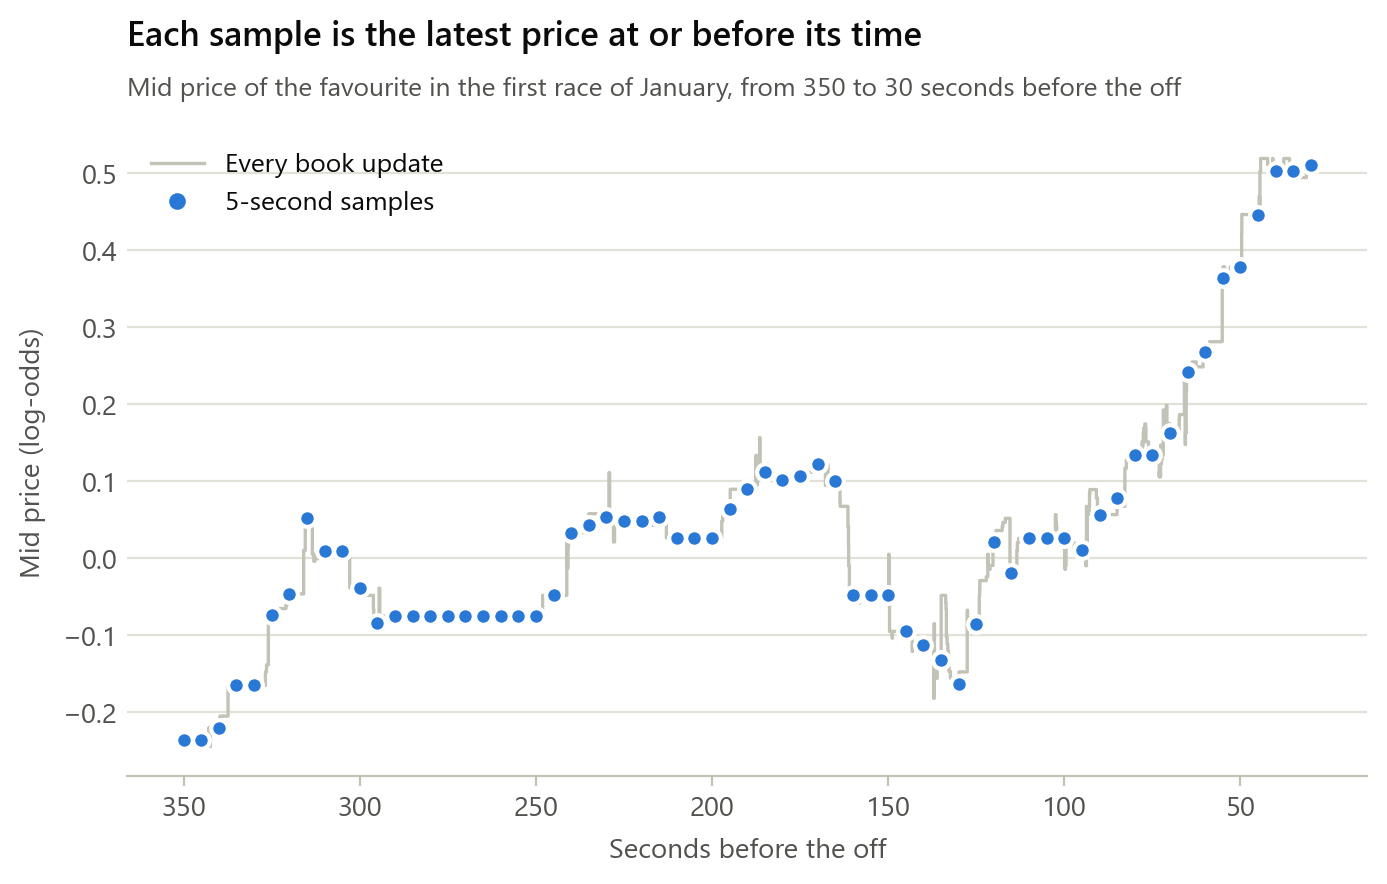

In [3]:
race = FILES[0]
first_race = mids[mids["race"] == race.stem]
favourite = first_race[first_race["ttj"] == 350].sort_values("odds")["selection_id"].iloc[0]

# The favourite's full price path in the window
book = pd.read_parquet(race)
book = book[(book["selection_id"] == favourite) & (book["status"] == "OPEN")]
ttj = (book["market_time"].iloc[-1] - book["publish_time"]).dt.total_seconds()
S = 0.5 * (1 / book["back_price_1"] + 1 / book["lay_price_1"])
window = ttj.between(30, 350)

samples = first_race[first_race["selection_id"] == favourite]

fig, ax = plt.subplots()
ax.step(ttj[window], np.log(S / (1 - S))[window], where="post", color=LIGHT, lw=1.2, label="Every book update")
ax.plot(samples["ttj"], samples["x"], "o", color=BLUE, ms=6, label="5-second samples")
ax.invert_xaxis()   # time runs left to right, towards the off
ax.set_xticks([350, 300, 250, 200, 150, 100, 50])
ax.set(xlabel="Seconds before the off", ylabel="Mid price (log-odds)")
legend(ax, loc="upper left")
titles(ax, "Each sample is the latest price at or before its time",
       "Mid price of the favourite in the first race of January, from 350 to 30 seconds before the off")
plt.show()

## Step 2: 5-second price changes

For each runner, the change over each 5-second step is the later mid minus the earlier one:

$$\Delta x = x_{\text{later}} - x_{\text{earlier}}$$

We keep a change only if both mids exist and the runner's mid odds were between 1.2 and 6.0 **at the start** of the step.

**Why only at the start?** Some runners hover around the edges of the range, like a dog drifting from 5.8 out to 6.4. That's a big move. If we also required the odds to *finish* inside the range, we'd throw away exactly these big moves and understate σ². Checking only the start also matches how the strategy behaves: it decides whether to quote from the current price, then lives with wherever the price goes next. A runner that keeps crossing 6.0 simply contributes the steps that start inside the range.

**Time bins.** Each change goes in the bin of its **start** time. Bins are written as (lower, upper], e.g. (30, 45], and labelled by their upper edge. This matches the strategy's table, where each bin is named by its upper edge, and it gives the very first change (350 s → 345 s) a bin.

In [4]:
# Put each runner's samples in time order (350 s first), then pair each sample with the next one
mids = mids.sort_values(["race", "selection_id", "ttj"], ascending=[True, True, False])
later = mids.groupby(["race", "selection_id"])[["x", "odds"]].shift(-1)

moves = mids.assign(dx=later["x"] - mids["x"], odds_end=later["odds"])
moves = moves[moves["dx"].notna() & moves["odds"].between(MIN_ODDS, MAX_ODDS)].copy()

# Bin of the start time: (30, 45] -> 45, (45, 60] -> 60, ..., (300, 350] -> 350
moves["bin"] = pd.cut(moves["ttj"], BIN_EDGES, labels=BIN_EDGES[1:])

print(f"{len(moves):,} price changes from {moves['race'].nunique():,} races")
print(f"{(moves['dx'] == 0).mean():.0%} of them are exactly zero (the mid didn't move)")
print(f"Largest change: {moves['dx'].abs().max():.2f} in log-odds")

541,657 price changes from 3,957 races
48% of them are exactly zero (the mid didn't move)
Largest change: 1.41 in log-odds


## Step 3: Variance per second in each bin

In each bin, the estimate is the sample variance of the changes, divided by 5:

$$\hat\sigma_x^2 = \frac{1}{5}\cdot\frac{1}{n-1}\sum_{i=1}^{n}\left(\Delta x_i - \overline{\Delta x}\right)^2$$

Dividing by 5 turns "per 5 seconds" into "per second". If the price follows a random walk, the variances of separate seconds add up, so a 5-second change has 5 times the variance of a 1-second change.

**A shortcut we'll reuse.** The variance only needs three totals: the number of changes $n$, their sum $\sum \Delta x$, and their sum of squares $\sum \Delta x^2$, because

$$\sum\left(\Delta x_i - \overline{\Delta x}\right)^2 = \sum \Delta x_i^2 - \frac{\left(\sum \Delta x_i\right)^2}{n}$$

So we total up each race once, per bin. After that:

- the **pooled** estimate adds up every race's totals;
- a **bootstrap** sample adds up the totals of the races it drew, counting a race twice if it was drawn twice;
- a **daily** estimate adds up the totals of that day's races.

One small function, `sigma2`, then turns any set of totals into σ².

In [5]:
moves["dx2"] = moves["dx"] ** 2
totals = (moves.groupby(["race", "bin"], observed=False)
               .agg(n=("dx", "size"), sum_dx=("dx", "sum"), sum_dx2=("dx2", "sum"))
               .unstack("bin", fill_value=0))
# totals["n"] is a table with one row per race and one column per bin; same for "sum_dx" and "sum_dx2"


def sigma2(n, sum_dx, sum_dx2, step=STEP):
    # Variance per second of changes over `step` seconds, from the three totals
    return (sum_dx2 - sum_dx**2 / n) / (n - 1) / step


pooled = sigma2(totals["n"].sum(), totals["sum_dx"].sum(), totals["sum_dx2"].sum())

# Sanity check: the shortcut gives the same answer as pandas' own variance
assert np.allclose(pooled, moves.groupby("bin", observed=False)["dx"].var() / STEP)

SCALE = 1e4   # show σ² in units of 10⁻⁴ per second, so 2.0 means 0.0002
pd.DataFrame({"changes": totals["n"].sum(), "σ² (×10⁻⁴)": (pooled * SCALE).round(2)})

,changes,σ² (×10⁻⁴)
bin,,
45,25996,2.14
60,26019,2.47
90,52084,2.05
120,52062,1.69
180,104129,1.69
240,102299,1.76
300,99080,1.82
350,79988,1.40


### Two robustness checks

Two things could skew the estimate, so here it is recomputed each way:

1. **Filtering on both ends.** If the odds also had to *finish* inside 1.2–6.0, the big moves out of the range would be thrown away.
2. **Very large moves.** A handful of changes are bigger than 1 in log-odds (about 2.7× in the odds). Almost all come from one illiquid race with a very wide book (best back 3.8, best lay 11.0), where a stray order briefly flips the mid. Our adverse-selection work drops moves this size as "runner events".

In [6]:
both_ends = moves[moves["odds_end"].between(MIN_ODDS, MAX_ODDS)]
no_huge = moves[moves["dx"].abs() <= 1]
print(f"{len(moves) - len(both_ends):,} changes finish outside 1.2-6.0")
print(f"{len(moves) - len(no_huge):,} changes are bigger than 1 in log-odds")

pd.DataFrame({
    "main estimate": pooled * SCALE,
    "both ends in range": both_ends.groupby("bin", observed=False)["dx"].var() / STEP * SCALE,
    "without moves > 1": no_huge.groupby("bin", observed=False)["dx"].var() / STEP * SCALE,
}).round(2)

3,010 changes finish outside 1.2-6.0
7 changes are bigger than 1 in log-odds


,main estimate,both ends in range,without moves > 1
bin,,,
45,2.14,2.07,2.14
60,2.47,2.28,2.37
90,2.05,2.00,2.02
120,1.69,1.63,1.69
180,1.69,1.63,1.65
240,1.76,1.69,1.72
300,1.82,1.75,1.74
350,1.40,1.32,1.37


## Step 4: 95% confidence intervals (bootstrap by race)

We resample **whole races**, not individual price changes. Runners in the same race move together (when one shortens, others must drift, since the probabilities add up to 1), and news hits the whole race at once. Treating every change as independent would make the intervals too narrow.

The recipe:

1. Draw $R$ races at random with replacement, where $R$ is the number of races.
2. Recompute σ² from the drawn races. A race drawn twice counts twice.
3. Repeat 1,000 times, sort the results, and take the 25th and 975th smallest values.

With the totals from Step 3, a bootstrap sample is just "how many times was each race drawn?". Multiplying those counts by the race totals and adding up gives that sample's totals. `rng.multinomial` draws all 1,000 sets of counts at once. It's the same as picking $R$ races with replacement and counting how often each one came up.

In [7]:
R = len(totals)
draws = rng.multinomial(R, np.full(R, 1 / R), size=N_BOOT)   # draws[b, r] = times race r was picked in repeat b

boot = sigma2(draws @ totals["n"].to_numpy(),
              draws @ totals["sum_dx"].to_numpy(),
              draws @ totals["sum_dx2"].to_numpy())          # one row per repeat, one column per bin
boot = np.sort(boot, axis=0)
ci_low, ci_high = boot[24], boot[974]                         # 25th and 975th smallest of 1,000

## Step 5: Is it stable from day to day?

We repeat the estimate using one day's races at a time. If σ² jumped around a lot between days, a single month's average wouldn't be a reliable number to trade on. For each bin we record the median, minimum and maximum across the 31 days, and the **coefficient of variation** (CV = standard deviation ÷ mean). A CV of 0.2 means a typical day is about 20% away from the average.

In [8]:
race_day = mids.groupby("race")["day"].first()
by_day = totals.groupby(race_day).sum()                               # each day's totals
daily = sigma2(by_day["n"], by_day["sum_dx"], by_day["sum_dx2"])      # one row per day, one column per bin

## Results

All σ² values below are in units of $10^{-4}$ per second.

In [9]:
summary = pd.DataFrame({
    "changes": totals["n"].sum(),
    "σ²": pooled * SCALE,
    "95% CI low": ci_low * SCALE,
    "95% CI high": ci_high * SCALE,
    "daily median": daily.median() * SCALE,
    "daily min": daily.min() * SCALE,
    "daily max": daily.max() * SCALE,
    "daily CV": daily.std() / daily.mean(),
}).round(2)
summary.index = [f"({lo}, {hi}]" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])]
summary.index.name = "seconds before off"
summary

,changes,σ²,95% CI low,95% CI high,daily median,daily min,daily max,daily CV
seconds before off,,,,,,,,
"(30, 45]",25996,2.14,1.97,2.37,2.00,1.45,5.51,0.35
"(45, 60]",26019,2.47,2.28,2.73,2.39,1.78,5.57,0.29
"(60, 90]",52084,2.05,1.91,2.22,1.90,1.28,3.09,0.23
"(90, 120]",52062,1.69,1.61,1.78,1.64,1.23,2.74,0.20
"(120, 180]",104129,1.69,1.58,1.80,1.61,1.22,2.61,0.20
"(180, 240]",102299,1.76,1.65,1.87,1.69,1.15,2.69,0.20
"(240, 300]",99080,1.82,1.67,2.01,1.66,1.38,3.76,0.26
"(300, 350]",79988,1.40,1.29,1.52,1.37,0.79,2.69,0.23


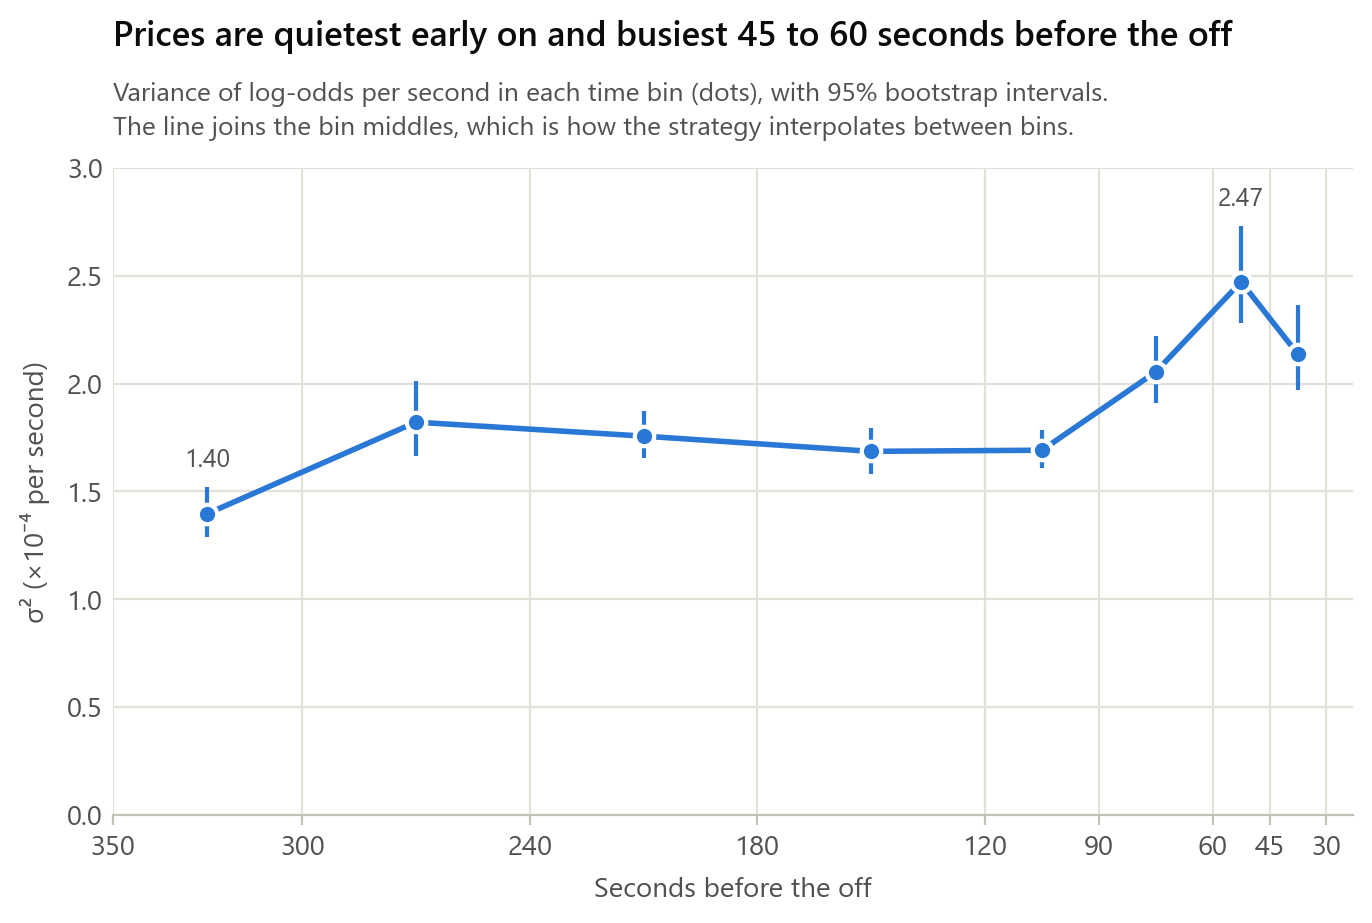

In [10]:
bin_middle = [(lo + hi) / 2 for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])]


def bin_axis(ax):
    # Time runs left to right towards the off, with a tick and a vertical hairline at every bin edge
    ax.invert_xaxis()
    ax.set_xticks(BIN_EDGES)
    ax.grid(True, axis="x")
    ax.set_xlabel("Seconds before the off")


fig, ax = plt.subplots()
ax.errorbar(bin_middle, pooled * SCALE, yerr=[(pooled - ci_low) * SCALE, (ci_high - pooled) * SCALE],
            fmt="-o", color=BLUE, elinewidth=1.5, capsize=0)
for i in (pooled.argmin(), pooled.argmax()):   # label the quietest and busiest bins
    ax.annotate(f"{pooled.iloc[i] * SCALE:.2f}", (bin_middle[i], ci_high[i] * SCALE),
                xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", color=INK_2, fontsize=9)
bin_axis(ax)
ax.set(ylabel="σ² (×10⁻⁴ per second)", ylim=(0, 3))
titles(ax, "Prices are quietest early on and busiest 45 to 60 seconds before the off",
       "Variance of log-odds per second in each time bin (dots), with 95% bootstrap intervals.\n"
       "The line joins the bin middles, which is how the strategy interpolates between bins.")
plt.show()

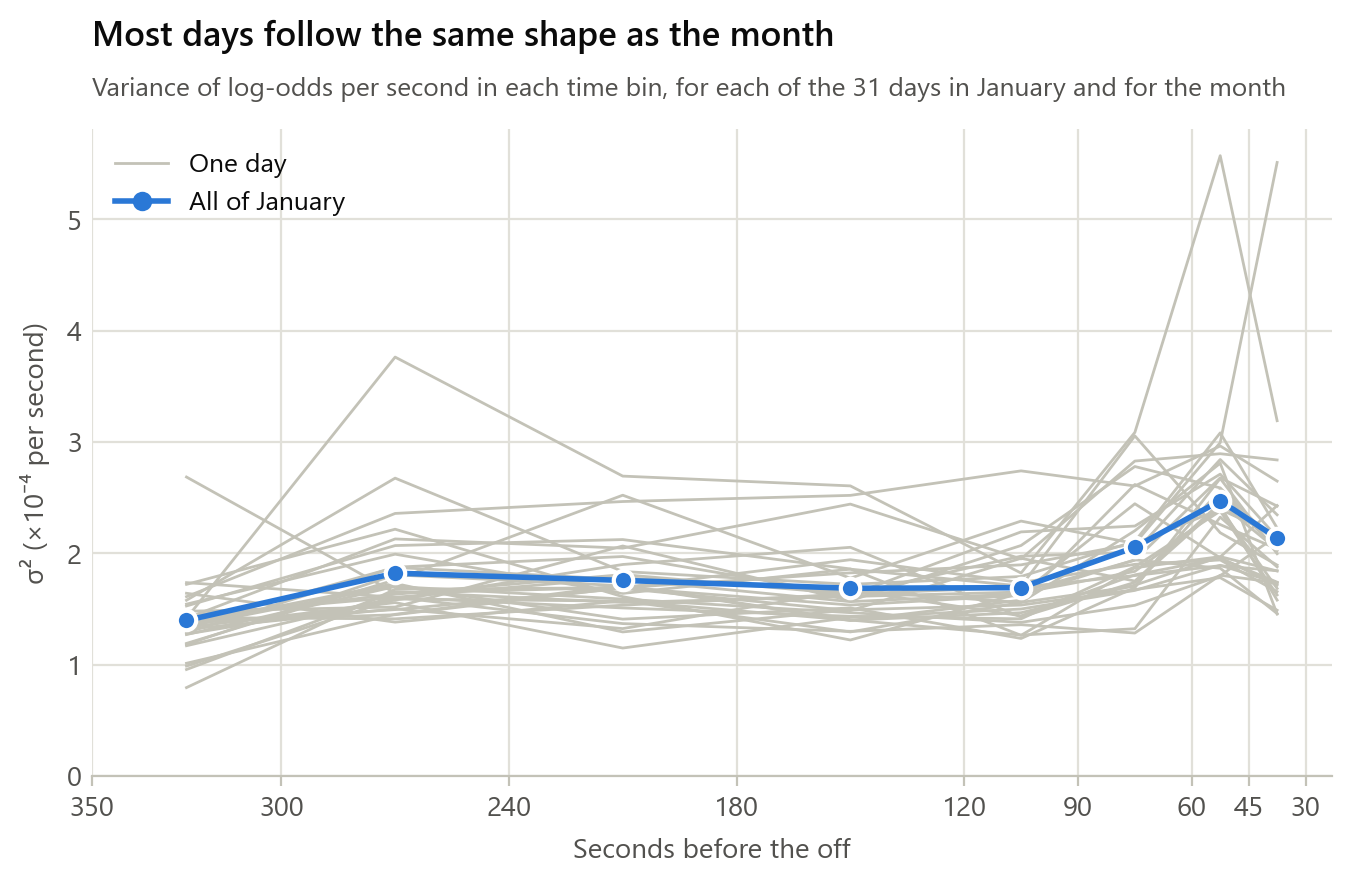

In [11]:
fig, ax = plt.subplots()
day_lines = ax.plot(bin_middle, daily.T * SCALE, color=LIGHT, lw=1)   # one line per day
day_lines[0].set_label("One day")
ax.plot(bin_middle, pooled * SCALE, "-o", color=BLUE, label="All of January")
bin_axis(ax)
ax.set(ylabel="σ² (×10⁻⁴ per second)", ylim=(0, None))
legend(ax, loc="upper left")
titles(ax, "Most days follow the same shape as the month",
       "Variance of log-odds per second in each time bin, for each of the 31 days in January and for the month")
plt.show()

## Table for the strategy

The strategy (`strategies/_final-strategy.py`) reads σ² as a list of `(upper edge in seconds, value)` and interpolates linearly between the bin middles. The last edge becomes `INF`, so the final value also covers anything further from the off.

In [12]:
edges = [str(e) for e in BIN_EDGES[1:-1]] + ["INF"]
print("SIGMA2_X = [" + ", ".join(f"({e}, {v:.2e})" for e, v in zip(edges, pooled)) + "]")

SIGMA2_X = [(45, 2.14e-04), (60, 2.47e-04), (90, 2.05e-04), (120, 1.69e-04), (180, 1.69e-04), (240, 1.76e-04), (300, 1.82e-04), (INF, 1.40e-04)]


## Reading the results

- **Shape.** Prices move least at the start of the window (1.4 × 10⁻⁴ per second, 300–350 s out). They are fairly flat at about 1.7–1.8 × 10⁻⁴ from 90 s to 300 s, then pick up in the last 90 seconds and peak at 2.5 × 10⁻⁴ at 45–60 s, about 1.8 times the early level. The final bin (30–45 s) is a little lower than the peak, though their intervals overlap.
- **In plain odds.** σ² = 2 × 10⁻⁴ per second means that over one minute the log-odds typically move by about $\sqrt{60 \times 0.0002} \approx 0.11$. For a dog at 3.0, that's a typical range of about 2.8 to 3.2 over a minute.
- **Precision.** With almost 4,000 races, every bin's 95% interval is within about 10% of its estimate.
- **Day to day.** A typical day is within 20–35% of the January value (daily CV 0.20–0.35). The bins nearest the off are the noisiest: they have the fewest changes per day, and a couple of very busy days reach 5.5 × 10⁻⁴. Those busy days also pull the pooled estimate a little above the typical day, which is why the daily medians sit slightly below it. Most days follow the same shape, so the pattern across bins is real and not one month's noise.
- **Robustness.** Requiring the odds to finish in range as well would understate σ² by 2–8%, as expected. Dropping the very large moves changes it by less than 5%. Neither check changes the picture, so we keep the main estimate.

**Converting to probability.** The strategy quotes in probability, not log-odds. Near a price $S$, a small change in log-odds moves the probability by about $S(1-S)$ times as much, and variance scales with the square, so

$$\sigma_p^2 = \sigma_x^2\,\big[S(1-S)\big]^2$$

This is what `ASGMStrategy._variance` does.

## Why 5-second steps?

Everything above measures price changes over 5-second steps. The step length is a choice, so here is why 5 seconds is a sensible one. Three things pull on it:

- **Very short steps count flicker as risk.** From one second to the next the mid often moves and then moves straight back, as small orders come and go at the best prices. Inventory we hold for minutes doesn't feel these blips, but they add to the variance, so very short steps overstate σ².
- **Long steps don't fit our bins.** The two bins nearest the off are only 15 seconds wide, and a change has to finish by 30 s before the off, when we stop quoting. A step longer than 15 seconds can't measure those bins at all, and longer steps leave fewer changes to estimate from.
- **The step should divide the bins evenly.** Every bin edge (30, 45, 60, 90, …, 350) is a multiple of 5, so with 5-second steps each bin holds a whole number of steps and no change straddles two bins. Five seconds is the longest step for which that's true: with 10-second steps, the change from 50 s to 40 s would straddle the edge at 45 s.

Five seconds is also the window we used to estimate the fill rate $k$, so both parameters are measured on the same clock.

To check the first point, and to see whether the exact choice matters, we redo Steps 1 to 3 with other step lengths. We sample every runner's mid **every second**, then keep every 2nd sample, every 4th, and so on. We only use steps that divide the 320-second window exactly (1, 2, 4, 5, 8, 10, 16, 20, 32, 40, 64 and 80 seconds), so every step length covers the same stretch of time.

If prices were a pure random walk, the variance per second would be the same whatever the step. Plotting it against the step length is known as a *volatility signature plot*.

In [13]:
SECONDS = np.arange(350, 29, -1)   # every second from 350 to 30 s before the off
per_second = pd.concat(Parallel(n_jobs=-1)(delayed(mids_on_grid)(f, SECONDS) for f in FILES), ignore_index=True)
per_second = per_second.sort_values(["race", "selection_id", "ttj"], ascending=[True, True, False])


def totals_for_step(step):
    # Steps 2 and 3 again, sampling every `step` seconds: per-race totals in each time bin
    sampled = per_second[(350 - per_second["ttj"]) % step == 0]
    later = sampled.groupby(["race", "selection_id"])["x"].shift(-1)
    changes = sampled.assign(dx=later - sampled["x"])
    changes = changes[changes["dx"].notna() & changes["odds"].between(MIN_ODDS, MAX_ODDS)]
    changes = changes.assign(dx2=changes["dx"] ** 2, bin=pd.cut(changes["ttj"], BIN_EDGES, labels=BIN_EDGES[1:]))
    per_race = (changes.groupby(["race", "bin"], observed=False)
                       .agg(n=("dx", "size"), sum_dx=("dx", "sum"), sum_dx2=("dx2", "sum"))
                       .unstack("bin", fill_value=0))
    # Keep Step 3's races, so its bootstrap draws line up. This only drops one race, which has a single
    # 1-second change (out of 2.7 million) and no 5-second changes.
    return per_race.reindex(totals.index, fill_value=0)


STEPS = [1, 2, 4, 5, 8, 10, 16, 20, 32, 40, 64, 80]   # the steps up to 80 s that divide 320 s exactly
by_step = {step: totals_for_step(step) for step in STEPS}
assert np.allclose(by_step[5], totals)                 # 5-second steps reproduce Step 3 exactly


def by_bin(t, step, weights=None):
    # σ² in each bin; with bootstrap weights, one row per repeat
    if weights is None:
        return sigma2(t["n"].sum(), t["sum_dx"].sum(), t["sum_dx2"].sum(), step)
    n, s, s2 = (t[c].to_numpy() for c in ("n", "sum_dx", "sum_dx2"))
    return sigma2(weights @ n, weights @ s, weights @ s2, step)


def all_bins(t, step, weights=None):
    # σ² from every bin together (a race's changes in all bins added up)
    n, s, s2 = (t[c].to_numpy().sum(axis=1) for c in ("n", "sum_dx", "sum_dx2"))
    if weights is None:
        return sigma2(n.sum(), s.sum(), s2.sum(), step)
    return sigma2(weights @ n, weights @ s, weights @ s2, step)


# Compare each step with 5 s using the same bootstrap draws for both, so the intervals are for the difference
five, five_boot = all_bins(by_step[5], 5), all_bins(by_step[5], 5, draws)
rows = []
for step, t in by_step.items():
    ratio = np.sort(all_bins(t, step, draws) / five_boot)
    rows.append({"step (s)": step, "changes": int(t["n"].to_numpy().sum()), "σ² (×10⁻⁴)": all_bins(t, step) * SCALE,
                 "vs 5 s (%)": 100 * (all_bins(t, step) / five - 1),
                 "95% CI low (%)": 100 * (ratio[24] - 1), "95% CI high (%)": 100 * (ratio[974] - 1)})
signature = pd.DataFrame(rows).set_index("step (s)")
signature.round(2)

,changes,σ² (×10⁻⁴),vs 5 s (%),95% CI low (%),95% CI high (%)
step (s),,,,,
1,2710091,1.89,6.21,4.56,8.12
2,1354805,1.81,2.01,0.34,4.09
4,677200,1.79,0.44,-1.09,2.37
5,541657,1.78,0.00,0.00,0.00
8,338374,1.79,0.83,-0.14,1.90
10,270600,1.79,0.62,-1.39,2.15
16,168987,1.81,2.02,-1.92,4.72
20,135066,1.83,2.81,-1.03,5.56
32,84294,1.85,3.85,-0.30,7.10


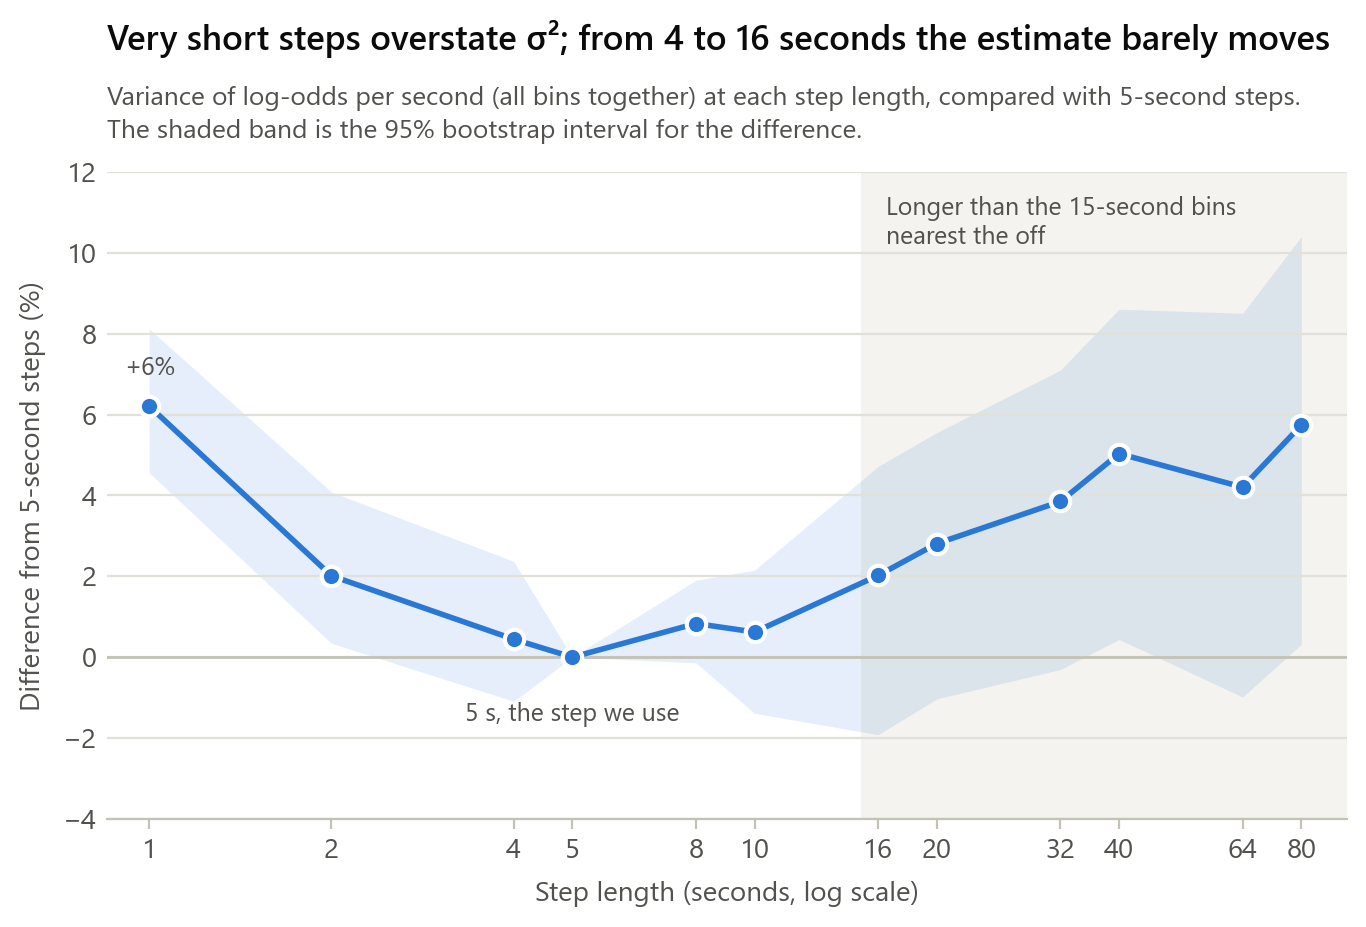

In [14]:
fig, ax = plt.subplots()
ax.axvspan(15, 100, color="#f4f3ef", lw=0, zorder=0)   # steps longer than the 15-second bins
ax.axhline(0, color=LIGHT, lw=1)
ax.fill_between(signature.index, signature["95% CI low (%)"], signature["95% CI high (%)"],
                color=BLUE, alpha=0.12, lw=0)
ax.plot(signature.index, signature["vs 5 s (%)"], "-o", color=BLUE)
ax.set_xscale("log", base=2)
ax.set_xticks(STEPS, labels=[str(s) for s in STEPS])
ax.minorticks_off()
ax.set_xlim(0.85, 95)
ax.set_ylim(-4, 12)
ax.text(16.5, 11.4, "Longer than the 15-second bins\nnearest the off", color=INK_2, fontsize=9, va="top")
ax.annotate("5 s, the step we use", (5, 0), xytext=(0, -16), textcoords="offset points",
            ha="center", va="top", color=INK_2, fontsize=9)
ax.annotate(f"+{signature.loc[1, 'vs 5 s (%)']:.0f}%", (1, signature.loc[1, "vs 5 s (%)"]), xytext=(0, 9),
            textcoords="offset points", ha="center", va="bottom", color=INK_2, fontsize=9)
ax.set(xlabel="Step length (seconds, log scale)", ylabel="Difference from 5-second steps (%)")
titles(ax, "Very short steps overstate σ²; from 4 to 16 seconds the estimate barely moves",
       "Variance of log-odds per second (all bins together) at each step length, compared with 5-second steps.\n"
       "The shaded band is the 95% bootstrap interval for the difference.")
plt.show()

The overall figure hides where the flicker is. Here is each bin measured with 1-second and with 5-second steps (our estimate, with its 95% interval from Step 4).

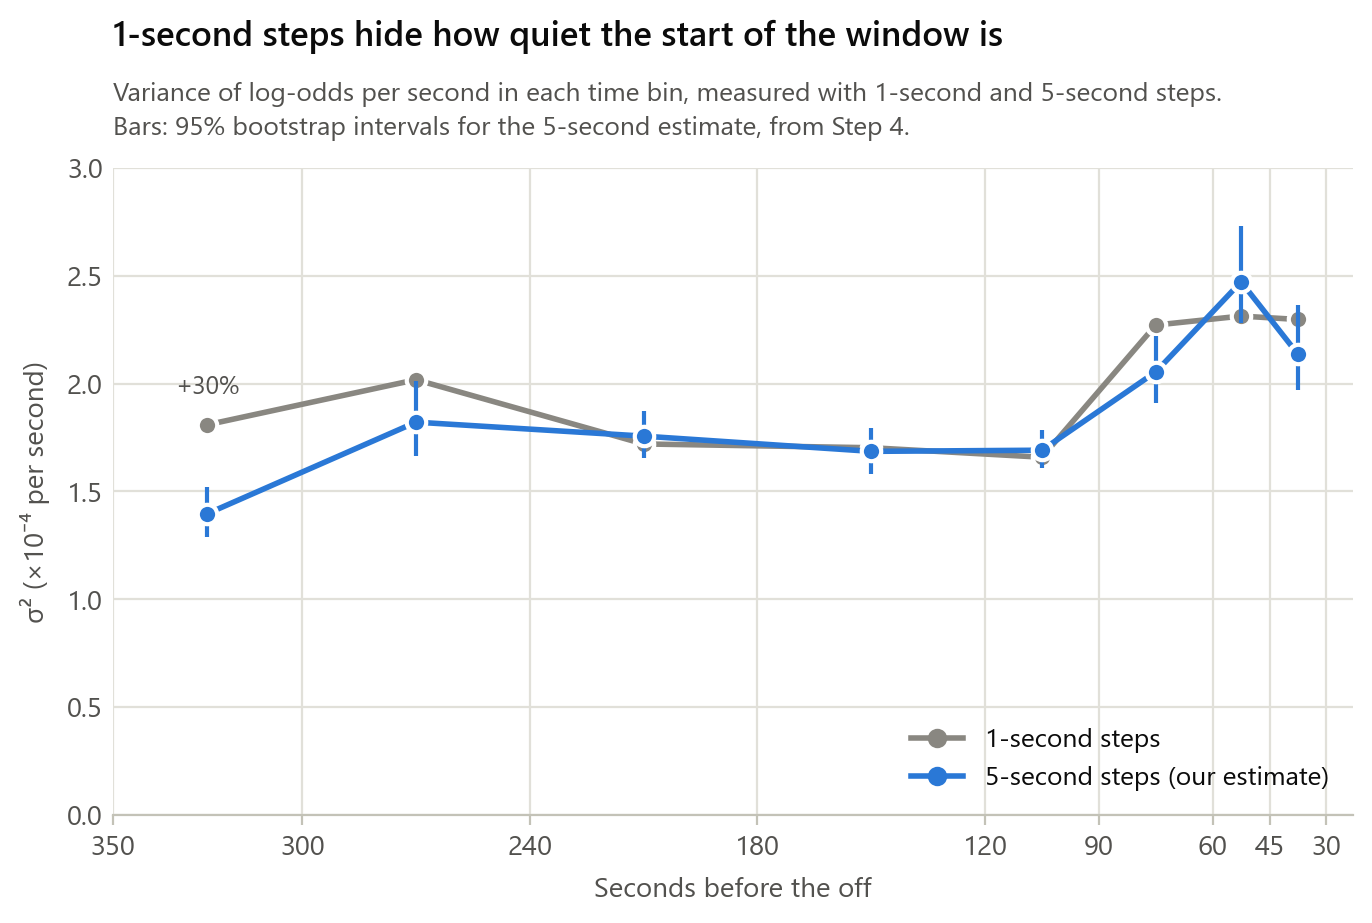

,1 s,5 s,difference (%),95% CI low (%),95% CI high (%)
seconds before off,,,,,
"(30, 45]",2.30,2.14,7.56,2.48,13.66
"(45, 60]",2.31,2.47,-6.43,-10.41,-2.65
"(60, 90]",2.27,2.05,10.58,1.60,25.94
"(90, 120]",1.66,1.69,-1.92,-3.91,0.08
"(120, 180]",1.70,1.69,1.00,-0.87,3.16
"(180, 240]",1.72,1.76,-2.07,-4.42,0.41
"(240, 300]",2.02,1.82,10.81,7.40,14.63
"(300, 350]",1.81,1.40,29.52,21.43,39.64


In [15]:
one = by_bin(by_step[1], 1)
ratio = np.sort(by_bin(by_step[1], 1, draws) / by_bin(by_step[5], 5, draws), axis=0)   # paired, per bin

fig, ax = plt.subplots()
ax.plot(bin_middle, one * SCALE, "-o", color=GREY, label="1-second steps")
ax.errorbar(bin_middle, pooled * SCALE, yerr=[(pooled - ci_low) * SCALE, (ci_high - pooled) * SCALE],
            fmt="none", ecolor=BLUE, elinewidth=1.5)
ax.plot(bin_middle, pooled * SCALE, "-o", color=BLUE, label="5-second steps (our estimate)")
earliest = len(bin_middle) - 1   # the (300, 350] bin
ax.annotate(f"+{100 * (one.iloc[earliest] / pooled.iloc[earliest] - 1):.0f}%",
            (bin_middle[earliest], one.iloc[earliest] * SCALE), xytext=(0, 9), textcoords="offset points",
            ha="center", va="bottom", color=INK_2, fontsize=9)
bin_axis(ax)
ax.set(ylabel="σ² (×10⁻⁴ per second)", ylim=(0, 3))
legend(ax, loc="lower right")
titles(ax, "1-second steps hide how quiet the start of the window is",
       "Variance of log-odds per second in each time bin, measured with 1-second and 5-second steps.\n"
       "Bars: 95% bootstrap intervals for the 5-second estimate, from Step 4.")
plt.show()

pd.DataFrame({
    "1 s": one * SCALE,
    "5 s": pooled * SCALE,
    "difference (%)": 100 * (one / pooled - 1),
    "95% CI low (%)": 100 * (ratio[24] - 1),
    "95% CI high (%)": 100 * (ratio[974] - 1),
}).set_axis(summary.index).round(2)

**What this shows**

- **1-second steps overstate σ²**, by about 6% overall. The extra is uneven: in the earliest bin (300–350 s) it's about 30%, which almost hides how quiet the start of the window is. The one bin that goes the other way is 45–60 s, where moves tend to carry on for a few seconds, so 1-second steps come out about 6% lower.
- **The flicker is gone within a few seconds.** From 4 to 16 seconds the estimate moves by 2% or less, so the exact step in that range hardly matters.
- **Longer steps creep up slowly**, by about 3% at 20 seconds and 5% at 40–80 seconds, though the intervals there are wide. Over a minute or more, prices drift a little more than a pure random walk would, so if anything 5-second steps slightly understate risk over long horizons. The gap is small next to the day-to-day spread (daily CV 0.20–0.35), and steps that long can't measure the bins near the off anyway.

So 5 seconds is the longest step that fits every bin evenly, it's long enough for the flicker to have washed out, and it still gives three changes per runner in each of the 15-second bins.